# TRAYECTORIAS COMPLETAS DE GBM PARA OPCIONES

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

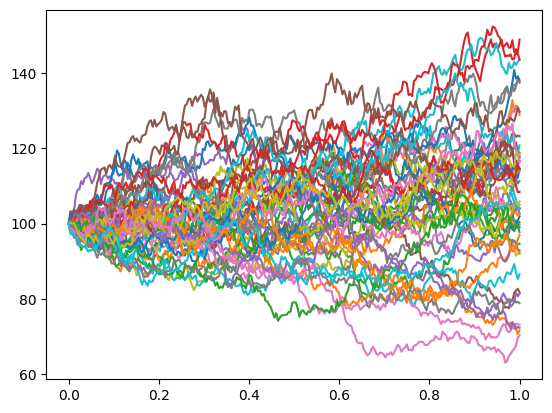

In [2]:
r=0.05
vol=0.20
s0=100
k=100
dt=1/252
m = 50
n = 252

rutas_individuales_1_año=[]
trayectorias=[]
for i in range(50):
    trayectoria=[s0]
    for i in range(252):
        z=np.random.normal(0,1)
        sT=trayectoria[-1] *np.exp((r-1/2*vol**2)*dt + (vol*np.sqrt(dt)*z))
        trayectoria.append(sT)
    rutas_individuales_1_año.append(trayectoria)
plt.figure()
t=np.linspace(0,1,253)
for x in rutas_individuales_1_año:
    plt.plot(t,x)



In [3]:
import matplotlib.pyplot as plt
import numpy as np

r = 0.05
vol = 0.20
s0 = 100

dt = 1/252

periodo = 252
rutas = 50

trayectorias = np.zeros((periodo + 1, rutas))

trayectorias[0] = s0

for i in range(1, periodo + 1):

    z = np.random.normal(0, 1, rutas)

    trayectorias[i] = trayectorias[i-1] * np.exp(
        (r - 0.5 * vol**2) * dt
        + vol * np.sqrt(dt) * z
    )


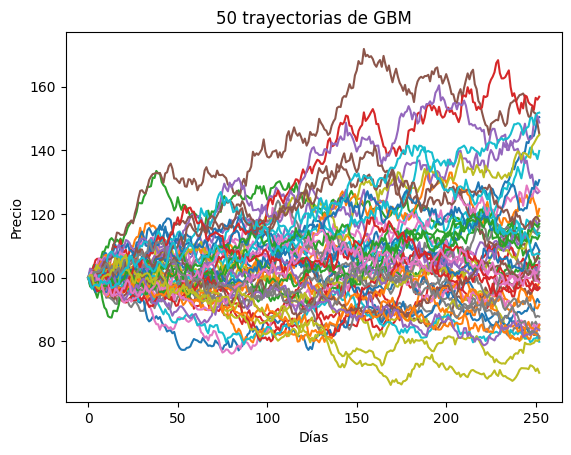

In [4]:
plt.plot(trayectorias)
plt.xlabel("Días")
plt.ylabel("Precio")
plt.title("50 trayectorias de GBM")
plt.show()

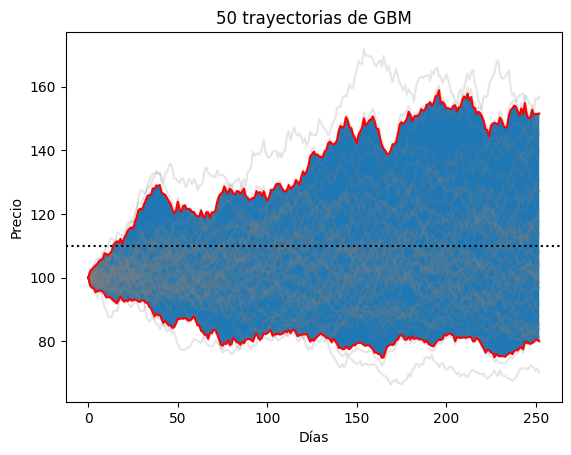

In [5]:
p975 = np.percentile(trayectorias, 97.5, axis=1)
p025 = np.percentile(trayectorias, 2.5, axis=1)
dias = np.arange(len(p025))

plt.plot(trayectorias, color="grey", alpha=0.2)
plt.plot(p975,color="red")
plt.plot(p025,color="red")
plt.fill_between(dias,p025,p975)
plt.xlabel("Días")
plt.axhline(110, color="black", linestyle=":")
plt.ylabel("Precio")
plt.title("50 trayectorias de GBM")
plt.show()

In [6]:
plt.fill_between?

Signature:
plt.fill_between(
    x: 'ArrayLike',
    y1: 'ArrayLike | float',
    y2: 'ArrayLike | float' = 0,
    where: 'Sequence[bool] | None' = None,
    interpolate: 'bool' = False,
    step: "Literal['pre', 'post', 'mid'] | None" = None,
    *,
    data=None,
    **kwargs,
) -> 'FillBetweenPolyCollection'
Docstring:
Fill the area between two horizontal curves.

The curves are defined by the points (*x*, *y1*) and (*x*,
*y2*).  This creates one or multiple polygons describing the filled
area.

You may exclude some horizontal sections from filling using *where*.

By default, the edges connect the given points directly.  Use *step*
if the filling should be a step function, i.e. constant in between
*x*.

Parameters
----------
x : array-like
    The x coordinates of the nodes defining the curves.

y1 : array-like or float
    The y coordinates of the nodes defining the first curve.

y2 : array-like or float, default: 0
    The y coordinates of the nodes defining the second curve.

whe

In [15]:
periodo = 252
rutas = 1000

trayectorias = np.zeros((periodo + 1, rutas))

trayectorias[0] = s0

medias = np.zeros(periodo + 1)
medias[0] = s0

for i in range(1, periodo + 1):

    z = np.random.normal(0, 1, rutas)

    trayectorias[i] = trayectorias[i-1] * np.exp(
        (r - 0.5 * vol**2) * dt
        + vol * np.sqrt(dt) * z
    )

medias_asiatica = np.mean(trayectorias[1:], axis=0)

Text(0.5, 1.0, 'medias ')

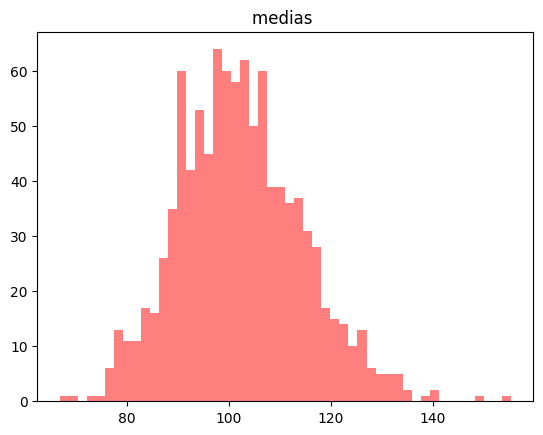

In [16]:
plt.hist(medias_asiatica, bins=50, color="red", alpha=0.5)
plt.title("medias ")
#plt.hist(trayectorias, bins=50, color="blue", alpha=0.5)


In [17]:
payoff_europea=np.mean(np.maximum(trayectorias[-1]-110,0))*np.exp(-r)
payoff_europea

np.float64(6.254282954988002)

In [19]:
payoff_asiatica=np.mean(np.maximum(medias_asiatica-110,0))*np.exp(-r)
payoff_asiatica

np.float64(1.994926558800996)

El de la asiatica es menor porque aplana la volatilidad de toda la trayectoria